# Conformal Prediction

Split conformal sobre las probabilidades de SEED (semilla 42): la validación calibra el umbral q̂ y el test se evalúa. Puntaje de no conformidad = 1 − P(clase verdadera); umbral = k-ésimo puntaje con k = ⌈(n+1)(1−α)⌉. Implementado en `src/eeg_uq/uncertainty/conformal.py` (sin librerías externas).

Conformal no cambia la detección (F1 = SEED) ni produce MI: su salida son conjuntos {fondo}, {huso}, {ambos} (ambiguo) o {} (vacío, abstención), con una garantía de cobertura **marginal** (promedio sobre todos los timesteps). Aquí se mide también la cobertura **por clase**, para ver si la garantía se cumple dentro de los husos.

Evaluaciones 0, 1 y 2, cinco folds cada una; media ± desviación estándar por evaluación y para las tres juntas.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

_candidates = [Path.cwd(), *Path.cwd().parents]
REPO_ROOT = next((p for p in _candidates if (p / 'configs' / 'default.yaml').exists()), Path.cwd())
if str(REPO_ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(REPO_ROOT / 'src'))
from eeg_uq import report

pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 250)


def show(figure):
    display(figure)
    plt.close(figure)

conformal = report.conformal_results()
COLUMNS = ['cobertura objetivo', 'cobertura total', 'cobertura husos', 'cobertura fondo', 'vacíos (abstención)', 'ambiguos', 'tamaño medio']

## 1. Cobertura y conjuntos por α

In [2]:
for alpha in sorted(conformal['alpha'].unique()):
    print('alpha = {:.2f}'.format(alpha))
    display(report.by_evaluation(conformal[conformal['alpha'] == alpha], COLUMNS))

alpha = 0.01
alpha = 0.05
alpha = 0.10
alpha = 0.20


,eval 0,eval 1,eval 2,"promedio eval 0, 1 y 2"
cobertura objetivo,0.99 ± 0,0.99 ± 0,0.99 ± 0,0.99 ± 1.1e-16
cobertura total,0.9895 ± 0.0015,0.9899 ± 0.00077,0.9895 ± 0.00082,0.9896 ± 0.001
cobertura husos,0.8704 ± 0.048,0.8729 ± 0.031,0.8763 ± 0.041,0.8732 ± 0.038
cobertura fondo,0.9959 ± 0.0024,0.9962 ± 0.0013,0.9954 ± 0.0018,0.9958 ± 0.0018
vacíos (abstención),0 ± 0,0 ± 0,0 ± 0,0 ± 0
ambiguos,0.0264 ± 0.0045,0.02601 ± 0.0035,0.0266 ± 0.0049,0.02634 ± 0.004
tamaño medio,1.026 ± 0.0045,1.026 ± 0.0035,1.027 ± 0.0049,1.026 ± 0.004


,eval 0,eval 1,eval 2,"promedio eval 0, 1 y 2"
cobertura objetivo,0.95 ± 0,0.95 ± 0,0.95 ± 0,0.95 ± 3.4e-16
cobertura total,0.9485 ± 0.0095,0.9498 ± 0.0042,0.9502 ± 0.0046,0.9495 ± 0.0061
cobertura husos,0.5659 ± 0.082,0.5613 ± 0.05,0.5876 ± 0.083,0.5716 ± 0.069
cobertura fondo,0.969 ± 0.012,0.9707 ± 0.005,0.9694 ± 0.0067,0.9697 ± 0.0076
vacíos (abstención),0.04509 ± 0.01,0.04413 ± 0.0045,0.04338 ± 0.0043,0.0442 ± 0.0064
ambiguos,0 ± 0,0 ± 0,0 ± 0,0 ± 0
tamaño medio,0.9549 ± 0.01,0.9559 ± 0.0045,0.9566 ± 0.0043,0.9558 ± 0.0064


,eval 0,eval 1,eval 2,"promedio eval 0, 1 y 2"
cobertura objetivo,0.9 ± 0,0.9 ± 0,0.9 ± 0,0.9 ± 1.1e-16
cobertura total,0.898 ± 0.02,0.8999 ± 0.0077,0.9001 ± 0.0098,0.8993 ± 0.013
cobertura husos,0.3049 ± 0.1,0.295 ± 0.054,0.3314 ± 0.085,0.3104 ± 0.078
cobertura fondo,0.9298 ± 0.022,0.9323 ± 0.0067,0.9304 ± 0.01,0.9308 ± 0.014
vacíos (abstención),0.1005 ± 0.02,0.09891 ± 0.0079,0.09862 ± 0.0097,0.09934 ± 0.013
ambiguos,0 ± 0,0 ± 0,0 ± 0,0 ± 0
tamaño medio,0.8995 ± 0.02,0.9011 ± 0.0079,0.9014 ± 0.0097,0.9007 ± 0.013


,eval 0,eval 1,eval 2,"promedio eval 0, 1 y 2"
cobertura objetivo,0.8 ± 0,0.8 ± 0,0.8 ± 0,0.8 ± 2.3e-16
cobertura total,0.7968 ± 0.035,0.8003 ± 0.013,0.8006 ± 0.019,0.7992 ± 0.022
cobertura husos,0.04885 ± 0.07,0.009615 ± 0.013,0.03506 ± 0.041,0.03118 ± 0.047
cobertura fondo,0.8369 ± 0.036,0.8427 ± 0.013,0.8416 ± 0.017,0.8404 ± 0.022
vacíos (abstención),0.2031 ± 0.035,0.1996 ± 0.013,0.1992 ± 0.019,0.2006 ± 0.022
ambiguos,0 ± 0,0 ± 0,0 ± 0,0 ± 0
tamaño medio,0.7969 ± 0.035,0.8004 ± 0.013,0.8008 ± 0.019,0.7994 ± 0.022


## 2. Cobertura total y por clase

Línea punteada: cobertura objetivo 1 − α. La cobertura total sigue al objetivo, pero la de los husos queda muy por debajo: la garantía la sostiene el fondo (~95% de los timesteps).

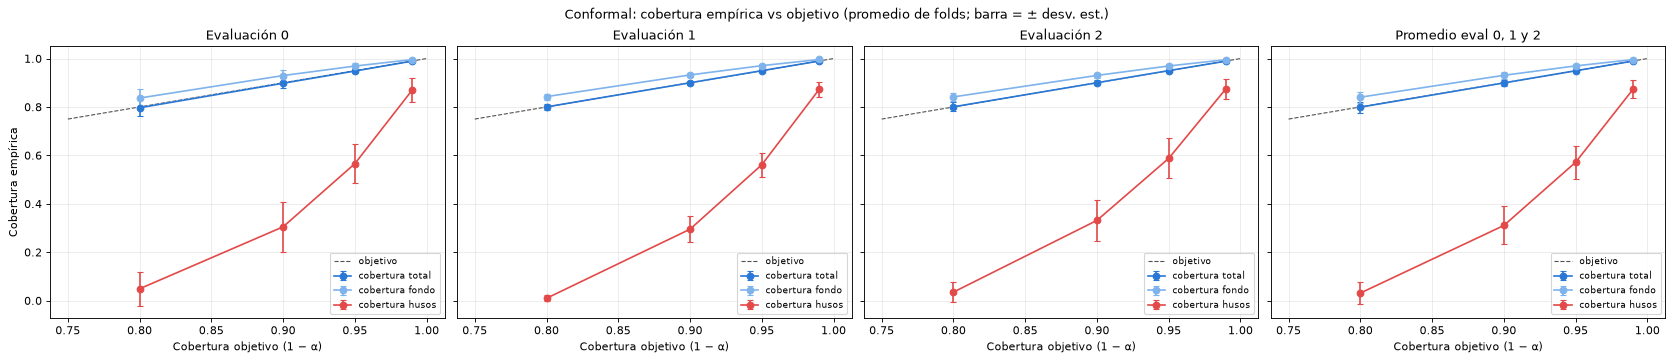

In [3]:
fig, axes = plt.subplots(1, len(report.SCOPES), figsize=(5.2 * len(report.SCOPES), 4.4), sharey=True, constrained_layout=True)
fig.suptitle('Conformal: cobertura empírica vs objetivo (promedio de folds; barra = ± desv. est.)')
for ax, (label, part) in zip(axes, [(f'Evaluación {e}', conformal[conformal['evaluación'] == e]) for e in report.EVALUATIONS] + [(report.MEAN_SCOPE, conformal)]):
    stats = part.groupby('cobertura objetivo')[['cobertura total', 'cobertura husos', 'cobertura fondo']].agg(['mean', 'std'])
    for column, color in (('cobertura total', '#2a78d6'), ('cobertura fondo', '#7fb3ec'), ('cobertura husos', '#e34948')):
        ax.errorbar(stats.index, stats[(column, 'mean')], yerr=stats[(column, 'std')], fmt='o-', capsize=3, color=color, label=column)
    ax.plot([0.75, 1.0], [0.75, 1.0], '--', color=report.CHANCE, lw=1, label='objetivo')
    ax.set(title=label, xlabel='Cobertura objetivo (1 − α)')
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)
axes[0].set_ylabel('Cobertura empírica')
show(fig)

## 3. Cómo se expresa la incertidumbre

Con α pequeño aparecen conjuntos ambiguos (ambas clases); con α mayores, conjuntos vacíos (abstención).

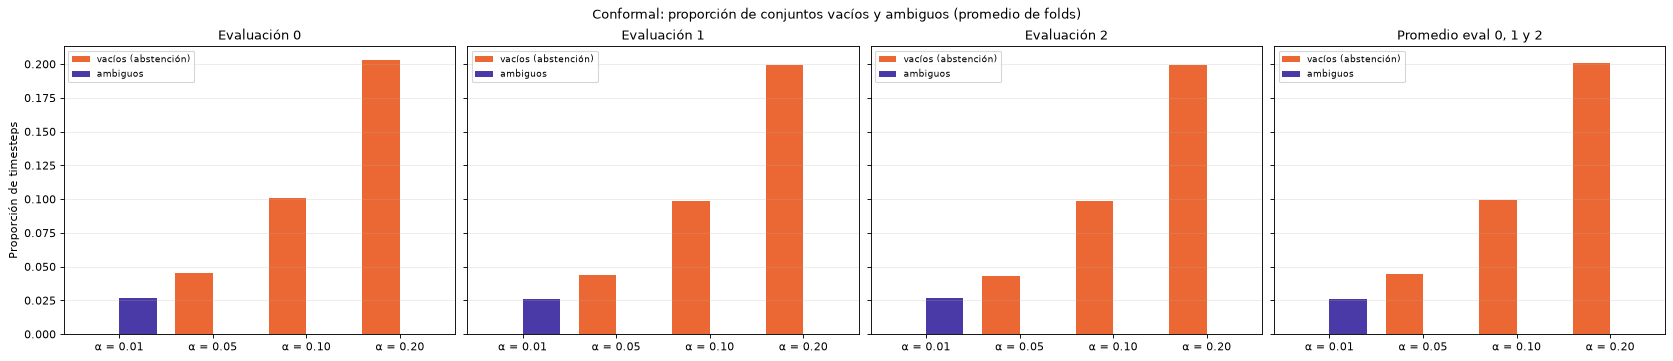

In [4]:
fig, axes = plt.subplots(1, len(report.SCOPES), figsize=(5.2 * len(report.SCOPES), 4.4), sharey=True, constrained_layout=True)
fig.suptitle('Conformal: proporción de conjuntos vacíos y ambiguos (promedio de folds)')
for ax, (label, part) in zip(axes, [(f'Evaluación {e}', conformal[conformal['evaluación'] == e]) for e in report.EVALUATIONS] + [(report.MEAN_SCOPE, conformal)]):
    stats = part.groupby('alpha')[['vacíos (abstención)', 'ambiguos']].mean()
    x = range(len(stats))
    ax.bar([i - 0.2 for i in x], stats['vacíos (abstención)'], 0.4, color='#eb6834', label='vacíos (abstención)')
    ax.bar([i + 0.2 for i in x], stats['ambiguos'], 0.4, color='#4a3aa7', label='ambiguos')
    ax.set_xticks(list(x), ['α = {:.2f}'.format(a) for a in stats.index])
    ax.set(title=label)
    ax.grid(axis='y', alpha=0.25)
    ax.legend(fontsize=8)
axes[0].set_ylabel('Proporción de timesteps')
show(fig)

## 4. Aciertos, falsos positivos y falsos negativos

La incertidumbre de Conformal en cada evento es la **fracción de timesteps no singleton** (vacíos o ambiguos) con α = 0.05. TP y FP se miden en el tramo predicho y TP y FN en el tramo real, igual que en los demás métodos. Como referencia se incluye la entropía de SEED (*SEED H(p)*). Conformal no tiene MI: es un solo modelo.

Primero la media y la mediana por tipo de evento; luego qué tan bien cada medida separa FP de TP y FN de TP (AUROC y AUPRC, con el AUPRC de azar = proporción de FP o FN).

In [5]:
import numpy as np
from eeg_uq.method_summary import event_uncertainty, load_fold
from eeg_uq.uncertainty.conformal import build_prediction_sets, compute_nonconformity_scores, fit_conformal_threshold

ALPHA = 0.05
MEASURE = 'fracción no singleton'
frames = []
for evaluation in report.EVALUATIONS:
    for fold in report.FOLDS:
        with np.load(report.method_path('SEED', evaluation, fold, 'validation')) as calibration:
            q_hat = fit_conformal_threshold(compute_nonconformity_scores(
                calibration['probabilities'], calibration['y_true'], calibration['valid_mask']), ALPHA)
        seed = load_fold(report.method_path('SEED', evaluation, fold), 'seed')
        sets = build_prediction_sets(seed['probability'], q_hat, seed['valid_mask'])
        uncertain = (sets['set_size'] != 1).astype(float)
        part = event_uncertainty(seed, extra={MEASURE: uncertain, 'SEED H(p)': seed['total']})
        part['grupo'] = part['tipo'] + ' (' + part['tramo'] + ')'
        frames.append(part.assign(**{'evaluación': evaluation, 'fold': fold}))
events = pd.concat(frames, ignore_index=True)

summary = {}
for label, part in [(f'eval {e}', events[events['evaluación'] == e]) for e in report.EVALUATIONS] + [(report.MEAN_SCOPE.lower(), events)]:
    stats = part.groupby('grupo')[MEASURE].agg(['mean', 'median', lambda v: (v > 0).mean(), 'size']).loc[report.GROUPS]
    stats.columns = ['media', 'mediana', 'eventos con alguna abstención', 'n']
    summary[label] = stats
display(pd.concat(summary, axis=1).round(3))

eval 0                                             eval 1                                             eval 2                                             promedio eval 0, 1 y 2                                             
               media mediana eventos con alguna abstención     n  media mediana eventos con alguna abstención     n  media mediana eventos con alguna abstención     n                  media mediana eventos con alguna abstención      n
grupo                                                                                                                                                                                                                                     
TP (predicho)  0.410   0.263                         1.000  4379  0.407   0.263                         1.000  4355  0.384   0.238                         1.000  4461                  0.400   0.250                         1.000  13195
FP (predicho)  0.840   1.000                         1.000   907  0.837   1.000                         1.000   804  0.817   1.000                         1.000   971                  0.831   1.000                         1.000   2682
TP (real)      0.369   0.226                         0.958  4379  0.368   0.235                         0.968  4355  0.341   0.202                         0.949  4461                  0.359   0.223                         0.958  13195
FN (real)      0.485   0.522                         0.651   962  0.528   0.689                         0.680   986  0.491   0.562                         0.695   880                  0.502   0.602                         0.675   2828

In [6]:
def separation_folds(events, negative, positive):
    rows = []
    for (evaluation, fold), group in events.groupby(['evaluación', 'fold']):
        group = group[group['grupo'].isin([negative, positive])]
        target = (group['grupo'] == positive).to_numpy()
        row = {'evaluación': evaluation, 'fold': fold, 'azar AUPRC': target.mean()}
        for measure in (MEASURE, 'SEED H(p)'):
            row[f'AUROC {measure}'] = report._auc(target, group[measure].to_numpy())
            row[f'AUPRC {measure}'] = report._auc(target, group[measure].to_numpy(), average=True)
        rows.append(row)
    return pd.DataFrame(rows)


print('FP vs TP (tramo predicho)')
display(report.by_evaluation(separation_folds(events, 'TP (predicho)', 'FP (predicho)')))
print('FN vs TP (tramo real)')
display(report.by_evaluation(separation_folds(events, 'TP (real)', 'FN (real)')))

FP vs TP (tramo predicho)
FN vs TP (tramo real)


,eval 0,eval 1,eval 2,"promedio eval 0, 1 y 2"
azar AUPRC,0.165 ± 0.063,0.1538 ± 0.029,0.1759 ± 0.035,0.1649 ± 0.043
AUROC fracción no singleton,0.8324 ± 0.011,0.8273 ± 0.014,0.8305 ± 0.031,0.8301 ± 0.019
AUPRC fracción no singleton,0.3992 ± 0.13,0.3797 ± 0.066,0.4288 ± 0.1,0.4026 ± 0.096
AUROC SEED H(p),0.856 ± 0.0099,0.8508 ± 0.011,0.8508 ± 0.03,0.8525 ± 0.018
AUPRC SEED H(p),0.4557 ± 0.13,0.4522 ± 0.063,0.484 ± 0.11,0.464 ± 0.098


,eval 0,eval 1,eval 2,"promedio eval 0, 1 y 2"
azar AUPRC,0.1792 ± 0.065,0.1854 ± 0.031,0.1656 ± 0.028,0.1767 ± 0.042
AUROC fracción no singleton,0.5206 ± 0.074,0.5457 ± 0.05,0.5399 ± 0.025,0.5354 ± 0.051
AUPRC fracción no singleton,0.229 ± 0.042,0.2604 ± 0.037,0.2213 ± 0.022,0.2369 ± 0.037
AUROC SEED H(p),0.5981 ± 0.084,0.6278 ± 0.042,0.6326 ± 0.044,0.6195 ± 0.058
AUPRC SEED H(p),0.2232 ± 0.041,0.26 ± 0.032,0.2283 ± 0.016,0.2372 ± 0.034


## 5. Gráficos de cajón por tipo de evento

Fracción no singleton de cada evento en **percentil dentro del fold** (así los folds son comparables). La línea punteada en 0.5 es el azar: si la caja de FP o FN queda sobre ella, Conformal se abstiene más en esos eventos que en los aciertos. Línea negra = mediana, línea roja = media.

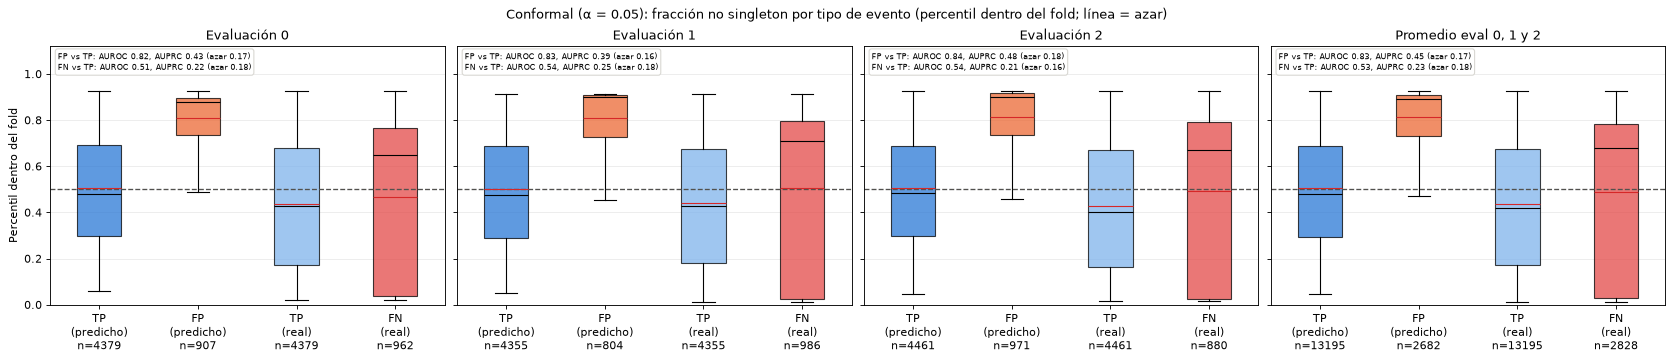

In [7]:
events['percentil'] = events.groupby(['evaluación', 'fold'])[MEASURE].rank(pct=True)
fig, axes = report._panels(f'Conformal (α = {ALPHA}): fracción no singleton por tipo de evento (percentil dentro del fold; línea = azar)')
for ax, (label, part) in zip(axes, report._scopes(events)):
    values = [part.loc[part['grupo'] == g, 'percentil'].dropna().to_numpy() for g in report.GROUPS]
    names = [g.replace(' (', '\n(') + f'\nn={len(v)}' for g, v in zip(report.GROUPS, values)]
    box = ax.boxplot(values, patch_artist=True, showmeans=True, meanline=True, showfliers=False, tick_labels=names,
                     medianprops={'color': 'black'}, meanprops={'color': '#d62728', 'linestyle': '-'})
    for patch, group in zip(box['boxes'], report.GROUPS):
        patch.set_facecolor(report.GROUP_COLORS[group])
        patch.set_alpha(0.75)
    ax.axhline(0.5, ls='--', color=report.CHANCE, lw=1.2)
    text = []
    for name, groups, positive in (('FP vs TP', report.GROUPS[:2], 'FP (predicho)'), ('FN vs TP', report.GROUPS[2:], 'FN (real)')):
        sub = part[part['grupo'].isin(groups)]
        target = (sub['grupo'] == positive).to_numpy()
        score = sub['percentil'].to_numpy()
        text.append(f'{name}: AUROC {report._auc(target, score):.2f}, '
                    f'AUPRC {report._auc(target, score, True):.2f} (azar {target.mean():.2f})')
    ax.text(0.02, 0.98, '\n'.join(text), transform=ax.transAxes, va='top', fontsize=7.5,
            bbox={'facecolor': 'white', 'edgecolor': '#d9d8d3', 'boxstyle': 'round'})
    ax.set(title=label, ylim=(0, 1.12))
    ax.grid(axis='y', alpha=0.25)
axes[0].set_ylabel('Percentil dentro del fold')
show(fig)

## Hallazgos

Promedio de las tres evaluaciones (los resultados por evaluación son casi idénticos).

1. **La garantía marginal se cumple:** cobertura 0.990 / 0.950 / 0.899 / 0.799 para objetivos de 0.99 / 0.95 / 0.90 / 0.80.
2. **Pero la sostiene el fondo.** La cobertura en los husos es 0.87 / 0.57 / 0.31 / 0.03 para α = 0.01 / 0.05 / 0.10 / 0.20, mientras el fondo supera el objetivo. Con α = 0.05, en ~43% de los timesteps de huso el conjunto no contiene la respuesta correcta.
3. **La incertidumbre se expresa de dos formas:** con α = 0.01 aparecen conjuntos ambiguos (2.6%); con α ≥ 0.05, solo conjuntos vacíos o abstención (4.4% con α = 0.05).
4. **La abstención señala los falsos positivos, no los negativos.** Con α = 0.05, la fracción de timesteps no singleton es 0.83 en los FP frente a 0.40 en los TP (AUROC FP vs TP 0.83, AUPRC 0.40 con azar 0.16), cerca de la entropía de SEED (0.85), de la que deriva. En los FN apenas separa (AUROC 0.54): cuando SEED pierde un huso, Conformal tampoco se abstiene.
5. **No cambia la detección** (F1 = SEED): Conformal reordena la probabilidad de SEED con un umbral, no agrega información.

**Trabajo futuro.** Conformal por clase (Mondrian), para garantizar la cobertura dentro de los husos y no solo en promedio.